# Simple logistic classifier

Using the color of each pixel in the image to classify if that pixel is floor or not. 

Being a pixel by pixel classifier the datasets will be datasets of pixels and not of images.

In [2]:
import h5py
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, binary_target_mask, make_data_splits, build_pixel_dataset

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, jaccard_score

DS_STEP = 8

In [3]:
nyu = NYUDepthV2(MAT_PATH)
target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]

In [4]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

X_train, y_train = build_pixel_dataset(nyu, train_indices, target_ids, DS_STEP)
X_test, y_test = build_pixel_dataset(nyu, test_indices, target_ids, DS_STEP)

Train images: 1028
Validation images: 206
Test images: 215


In [5]:
clf = LogisticRegression(class_weight="balanced", max_iter=1000)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["not floor", "floor"]))
print(f"floor IoU: {jaccard_score(y_test, y_pred):.3f}")

              precision    recall  f1-score   support

   not floor       0.93      0.55      0.69    775899
       floor       0.17      0.68      0.27    100664

    accuracy                           0.57    876563
   macro avg       0.55      0.62      0.48    876563
weighted avg       0.84      0.57      0.65    876563

floor IoU: 0.154


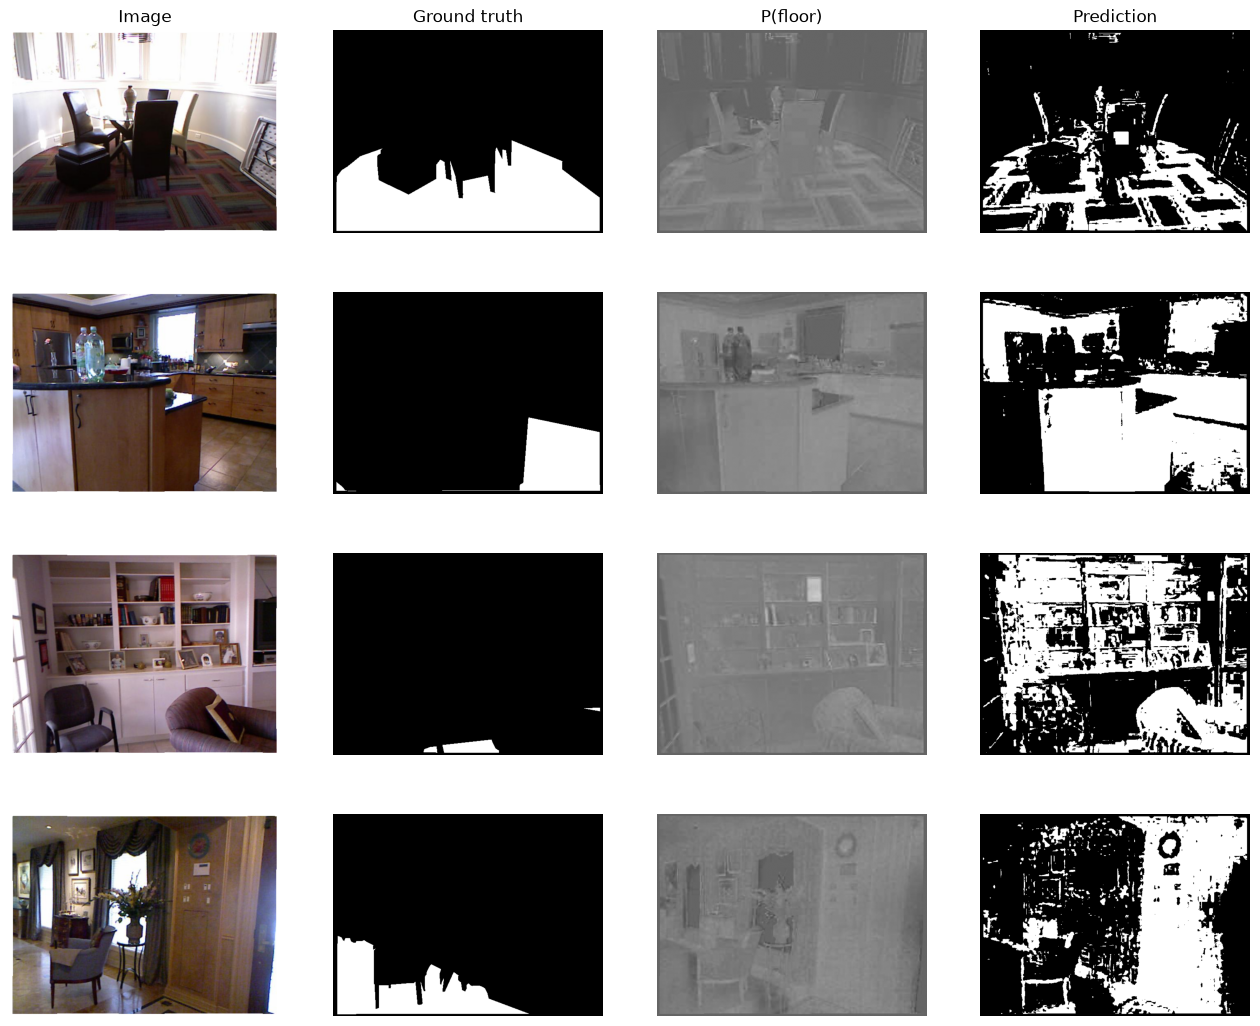

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))

for row, idx in enumerate(test_indices[:4]):
    image, labels = nyu.get_pair(idx)

    # Ground truth: 1 = floor, 0 = everything else
    gt = binary_target_mask(labels, target_ids)

    # Predict P(floor) for every pixel, then reshape back to image size
    X = image.reshape(-1, 3) / 255.0
    proba = clf.predict_proba(X)[:, 1].reshape(labels.shape)

    # Final prediction: floor if P(floor) >= 0.5
    pred = proba >= 0.5

    axes[row, 0].imshow(image)
    axes[row, 1].imshow(gt, cmap="gray")
    axes[row, 2].imshow(proba, cmap="gray", vmin=0, vmax=1)
    axes[row, 3].imshow(pred, cmap="gray")

axes[0, 0].set_title("Image")
axes[0, 1].set_title("Ground truth")
axes[0, 2].set_title("P(floor)")
axes[0, 3].set_title("Prediction")

for ax in axes.ravel():
    ax.axis("off")

plt.show()